In [1]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

dev_df = pd.read_csv("data/processed/dev_data.csv")
print(f"Development Set Loaded: {dev_df.shape}")

class DiamondsFeatureBuilder(BaseEstimator, TransformerMixin): 
    # """Builds the official 18-term candidate specification (Section 3.3).
    # Computes centering statistics purely on the training set to prevent leakage (Section 7.4).
    # """"

    def __init__(self):
        self.mean_depth_ = None
        self.mean_table_ = None

    def fit(self, X, y=None):
        self.mean_depth_ = X['depth'].mean()
        self.mean_table_ = X['table'].mean()
        return self

    def transform(self, X):
        df_out = pd.DataFrame(index=X.index)

        # 1-4: Size and shape terms
        df_out['log_carat'] = np.log(X['carat'])
        df_out['log_carat_sq'] = df_out['log_carat'] ** 2
        df_out['log_volume'] = np.log(X['x'] * X['y'] * X['z'])
        df_out['aspect_xy'] = X['x'] / X['y']

        # 5-8: Centered proportions and quadratics
        df_out['depth_c'] = X['depth'] - self.mean_depth_
        df_out['depth_c_sq'] = df_out['depth_c'] ** 2
        df_out['table_c'] = X['table'] - self.mean_table_
        df_out['table_c_sq'] = df_out['table_c'] ** 2

        # 9-14: Ordinal quality scores and non-linear quadratics
        df_out['cut_score'] = X['cut_score']
        df_out['cut_score_sq'] = X['cut_score'] ** 2
        df_out['color_score'] = X['color_score']
        df_out['color_score_sq'] = X['color_score'] ** 2
        df_out['clarity_score'] = X['clarity_score']
        df_out['clarity_score_sq'] = X['clarity_score'] ** 2

        # 15-18: Domain interactions
        df_out['carat_x_cut'] = df_out['log_carat'] * df_out['cut_score']
        df_out['carat_x_color'] = df_out['log_carat'] * df_out['color_score']
        df_out['carat_x_clarity'] = df_out['log_carat'] * df_out['clarity_score']
        df_out['table_x_cut'] = df_out['table_c'] * df_out['cut_score']

        return df_out

# Verify 18 terms
fb = DiamondsFeatureBuilder()
X_dev_18 = fb.fit_transform(dev_df)
print(f"Engineered Terms: {X_dev_18.shape[1]} terms (Expected: 18)")
print(list(X_dev_18.columns))

Development Set Loaded: (37739, 19)
Engineered Terms: 18 terms (Expected: 18)
['log_carat', 'log_carat_sq', 'log_volume', 'aspect_xy', 'depth_c', 'depth_c_sq', 'table_c', 'table_c_sq', 'cut_score', 'cut_score_sq', 'color_score', 'color_score_sq', 'clarity_score', 'clarity_score_sq', 'carat_x_cut', 'carat_x_color', 'carat_x_clarity', 'table_x_cut']


In [2]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm

def evaluate_predictions(y_true_dollars, pred_log_price, train_residuals=None):
  # """Evaluates model performance on the original dollar scale (Section 7.1 & 8.2).

  # Applies Duan's smearing correction factor if training log-residuals are
  # provided.
  # """

  if train_residuals is not None:
    smearing_factor = np.mean(np.exp(train_residuals))
    y_pred_dollars = np.exp(pred_log_price) * smearing_factor
  else:
    y_pred_dollars = np.exp(pred_log_price)

  rmse = np.sqrt(mean_squared_error(y_true_dollars, y_pred_dollars))
  mae = mean_absolute_error(y_true_dollars, y_pred_dollars)
  r2 = r2_score(y_true_dollars, y_pred_dollars)

  return {"RMSE ($)": round(rmse, 2), "MAE ($)": round(mae, 2), "R2": round(r2, 4)}

  # 1. Prepare Target and Predictors on Development Data
y_dev_log = dev_df["log_price"]
y_dev_dollar = dev_df["price"]

# Transform 18 terms
X_dev_18 = fb.fit_transform(dev_df)
X_dev_18_const = sm.add_constant(X_dev_18)

# 2. Baseline Model 1: Mean Baseline (Section 8.1)
mean_log_pred = np.full(len(dev_df), y_dev_log.mean())
res_mean = evaluate_predictions(y_dev_dollar, mean_log_pred)

# 3. Baseline Model 2: Carat-only OLS (Section 8.1)
X_carat = sm.add_constant(X_dev_18[["log_carat"]])
model_carat = sm.OLS(y_dev_log, X_carat).fit()
res_carat = evaluate_predictions(
    y_dev_dollar, model_carat.fittedvalues, model_carat.resid
)

# 4. Baseline Model 3: Carat + Quality Scores (Section 8.1)
quality_cols = ["log_carat", "cut_score", "color_score", "clarity_score"]
X_qual = sm.add_constant(X_dev_18[quality_cols])
model_qual = sm.OLS(y_dev_log, X_qual).fit()
res_qual = evaluate_predictions(
    y_dev_dollar, model_qual.fittedvalues, model_qual.resid
)

# 5. Full 18-Term OLS Model (Section 9.3 & 9.4)
model_full = sm.OLS(y_dev_log, X_dev_18_const).fit()
res_full = evaluate_predictions(
    y_dev_dollar, model_full.fittedvalues, model_full.resid
)

# Compile Baseline Ladder Table (Section 8.1 & 9.4)
baseline_summary = pd.DataFrame(
    [
        {"Model": "1. Mean Predictor", **res_mean, "AIC": np.nan, "BIC": np.nan},
        {
            "Model": "2. Carat-only (log_carat)",
            **res_carat,
            "AIC": round(model_carat.aic, 1),
            "BIC": round(model_carat.bic, 1),
        },
        {
            "Model": "3. Carat + Quality (Linear)",
            **res_qual,
            "AIC": round(model_qual.aic, 1),
            "BIC": round(model_qual.bic, 1),
        },
        {
            "Model": "4. Full 18-Term Specification",
            **res_full,
            "AIC": round(model_full.aic, 1),
            "BIC": round(model_full.bic, 1),
        },
    ]
)

display(baseline_summary)

from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Heteroscedasticity Test (Section 10.2)
bp_test = het_breuschpagan(model_full.resid, model_full.model.exog)
print(f"Breusch-Pagan LM p-value: {bp_test[1]:.4e}")
if bp_test[1] < 0.05:
  print(
      "-> Heteroscedasticity detected: Mandatory use of HC3 robust standard"
      " errors (Section 10.2 & 13.2)"
  )

# 2. Multicollinearity: Variance Inflation Factor (Section 10.4)
vif_data = pd.DataFrame()
vif_data["Term"] = X_dev_18.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_dev_18.values, i)
    for i in range(X_dev_18.shape[1])
]
print("\n=== Top VIF Factors (Section 10.4) ===")
display(vif_data.sort_values(by="VIF", ascending=False).head(8).round(2))

,Model,RMSE ($),MAE ($),R2,AIC,BIC
0,1. Mean Predictor,4279.03,2810.97,-0.1460,NaN,NaN
1,2. Carat-only (log_carat),1679.60,859.89,0.8234,6348.6,6365.7
2,3. Carat + Quality (Linear),974.70,462.32,0.9405,-37888.8,-37846.1
3,4. Full 18-Term Specification,914.70,424.09,0.9476,-43098.3,-42936.1


Breusch-Pagan LM p-value: 0.0000e+00
-> Heteroscedasticity detected: Mandatory use of HC3 robust standard errors (Section 10.2 & 13.2)

=== Top VIF Factors (Section 10.4) ===


,Term,VIF
0,log_carat,1072.17
2,log_volume,1053.50
8,cut_score,65.67
9,cut_score_sq,65.67
13,clarity_score_sq,30.93
12,clarity_score,27.25
11,color_score_sq,25.77
10,color_score,24.67


In [3]:
def backward_selection(X_df, y_s, criterion="aic"):
#   """Performs backward elimination on candidate features using AIC or BIC (Section 9.3).

#   Respects polynomial/interaction hierarchy: keeps main effects if quadratics or
#   interactions remain.
#   """
  current_features = list(X_df.columns)
  best_score = sm.OLS(y_s, sm.add_constant(X_df)).fit().aic
  if criterion == "bic":
    best_score = sm.OLS(y_s, sm.add_constant(X_df)).fit().bic

  while len(current_features) > 1:
    scores_with_candidates = []

    for candidate in current_features:
      # Hierarchy protection (Section 7.4): do not drop main effects while interactions exist
      if candidate == "log_carat" and any("carat" in f for f in current_features if f != "log_carat"):
        continue
      if candidate == "cut_score" and any("cut" in f for f in current_features if f != "cut_score"):
        continue
      if candidate == "color_score" and any("color" in f for f in current_features if f != "color_score"):
        continue
      if candidate == "clarity_score" and any("clarity" in f for f in current_features if f != "clarity_score"):
        continue
      if candidate == "depth_c" and "depth_c_sq" in current_features:
        continue
      if candidate == "table_c" and any("table" in f for f in current_features if f != "table_c"):
        continue

      features_subset = [f for f in current_features if f != candidate]
      model = sm.OLS(y_s, sm.add_constant(X_df[features_subset])).fit()
      score = model.aic if criterion == "aic" else model.bic
      scores_with_candidates.append((score, candidate))

    if not scores_with_candidates:
      break

    scores_with_candidates.sort()
    best_candidate_score, worst_feature = scores_with_candidates[0]

    # Only prune if the information criterion improves (Section 9.5)
    if best_candidate_score < best_score:
      best_score = best_candidate_score
      current_features.remove(worst_feature)
      print(
          f"Pruned: {worst_feature:<18} | New {criterion.upper()}:"
          f" {best_score:.2f}"
      )
    else:
      break

  return current_features


print("=== Running AIC Backward Elimination ===")
aic_features = backward_selection(X_dev_18, y_dev_log, criterion="aic")

print("\n=== Running BIC Backward Elimination ===")
bic_features = backward_selection(X_dev_18, y_dev_log, criterion="bic")

print(f"\nFinal AIC Feature Count: {len(aic_features)}")
print(f"Final BIC Feature Count: {len(bic_features)}")

=== Running AIC Backward Elimination ===

=== Running BIC Backward Elimination ===
Pruned: carat_x_cut        | New BIC: -42940.10

Final AIC Feature Count: 18
Final BIC Feature Count: 17


In [4]:
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Set up 5-fold CV on dev data (Section 6.3 & 11.3)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Candidate alpha grids (Section 11.4)
alphas = np.logspace(-4, 2, 25)
l1_ratios = [0.1, 0.5, 0.7, 0.9]


def evaluate_regularised_cv(model_type='ridge'):
  best_alpha = None
  best_l1 = None
  best_cv_rmse = float('inf')

  # Grid search inside CV folds
  if model_type == 'ridge':
    for a in alphas:
      fold_rmses = []
      for tr_idx, va_idx in kf.split(dev_df):
        tr_df, va_df = dev_df.iloc[tr_idx], dev_df.iloc[va_idx]
        pipe = Pipeline(
            [('feat', DiamondsFeatureBuilder()), ('scaler', StandardScaler()), ('reg', Ridge(alpha=a))]
        )
        pipe.fit(tr_df, tr_df['log_price'])
        # Predict & smearing evaluate on fold validation set
        train_resid = (
            tr_df['log_price'] - pipe.predict(tr_df)
        ).values
        val_pred = pipe.predict(va_df)
        score = evaluate_predictions(
            va_df['price'].values, val_pred, train_resid
        )
        fold_rmses.append(score['RMSE ($)'])
      mean_rmse = np.mean(fold_rmses)
      if mean_rmse < best_cv_rmse:
        best_cv_rmse = mean_rmse
        best_alpha = a
    return {
        'model': 'Ridge',
        'alpha': best_alpha,
        'l1_ratio': None,
        'CV_RMSE': best_cv_rmse,
    }

  elif model_type == 'lasso':
    for a in alphas:
      fold_rmses = []
      for tr_idx, va_idx in kf.split(dev_df):
        tr_df, va_df = dev_df.iloc[tr_idx], dev_df.iloc[va_idx]
        pipe = Pipeline(
            [('feat', DiamondsFeatureBuilder()), ('scaler', StandardScaler()), ('reg', Lasso(alpha=a, max_iter=5000))]
        )
        pipe.fit(tr_df, tr_df['log_price'])
        train_resid = (
            tr_df['log_price'] - pipe.predict(tr_df)
        ).values
        val_pred = pipe.predict(va_df)
        score = evaluate_predictions(
            va_df['price'].values, val_pred, train_resid
        )
        fold_rmses.append(score['RMSE ($)'])
      mean_rmse = np.mean(fold_rmses)
      if mean_rmse < best_cv_rmse:
        best_cv_rmse = mean_rmse
        best_alpha = a
    return {
        'model': 'Lasso',
        'alpha': best_alpha,
        'l1_ratio': None,
        'CV_RMSE': best_cv_rmse,
    }

  elif model_type == 'elastic_net':
    for l1 in l1_ratios:
      for a in alphas:
        fold_rmses = []
        for tr_idx, va_idx in kf.split(dev_df):
          tr_df, va_df = dev_df.iloc[tr_idx], dev_df.iloc[va_idx]
          pipe = Pipeline([
              ('feat', DiamondsFeatureBuilder()),
              ('scaler', StandardScaler()),
              ('reg', ElasticNet(alpha=a, l1_ratio=l1, max_iter=5000)),
          ])
          pipe.fit(tr_df, tr_df['log_price'])
          train_resid = (
              tr_df['log_price'] - pipe.predict(tr_df)
          ).values
          val_pred = pipe.predict(va_df)
          score = evaluate_predictions(
              va_df['price'].values, val_pred, train_resid
          )
          fold_rmses.append(score['RMSE ($)'])
        mean_rmse = np.mean(fold_rmses)
        if mean_rmse < best_cv_rmse:
          best_cv_rmse = mean_rmse
          best_alpha = a
          best_l1 = l1
    return {
        'model': 'Elastic Net',
        'alpha': best_alpha,
        'l1_ratio': best_l1,
        'CV_RMSE': best_cv_rmse,
    }


print('Tuning Ridge...')
ridge_res = evaluate_regularised_cv('ridge')
print('Tuning Lasso...')
lasso_res = evaluate_regularised_cv('lasso')
print('Tuning Elastic Net...')
enet_res = evaluate_regularised_cv('elastic_net')

cv_reg_summary = pd.DataFrame([ridge_res, lasso_res, enet_res])
display(cv_reg_summary)

Tuning Ridge...
Tuning Lasso...
Tuning Elastic Net...


/Users/max/Desktop/Osg/Quant/Diamond Proj/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.127060e+00, tolerance: 3.106e+00
  model = cd_fast.enet_coordinate_descent(


,model,alpha,l1_ratio,CV_RMSE
0,Ridge,56.234133,NaN,914.012
1,Lasso,0.000100,NaN,915.600
2,Elastic Net,0.001778,0.1,914.466


In [5]:
from statsmodels.stats.multitest import multipletests

# ---------------------------------------------------------
# Step 1: Stability Testing Across Repeated Folds (Section 12.2 & 12.3)
# ---------------------------------------------------------
# Candidate comparison: OLS Full, BIC OLS (17 terms), and Best Ridge
bic_cols = bic_features  # Extracted from earlier BIC backward selection

seeds = [42, 101, 2024, 999, 7]
stability_records = []
coef_tracker = {term: [] for term in bic_cols}

print("Running Repeated 5-Fold CV (5 seeds = 25 total folds)...")
for s in seeds:
  rep_kf = KFold(n_splits=5, shuffle=True, random_state=s)
  for tr_idx, va_idx in rep_kf.split(dev_df):
    tr, va = dev_df.iloc[tr_idx], dev_df.iloc[va_idx]

    # Transform using training fold constants
    fb_fold = DiamondsFeatureBuilder().fit(tr)
    X_tr_all = fb_fold.transform(tr)
    X_va_all = fb_fold.transform(va)

    # Fit BIC-selected specification
    X_tr_bic = sm.add_constant(X_tr_all[bic_cols])
    X_va_bic = sm.add_constant(X_va_all[bic_cols])

    model_rep = sm.OLS(tr["log_price"], X_tr_bic).fit()
    pred_va = model_rep.predict(X_va_bic)

    eval_res = evaluate_predictions(
        va["price"].values, pred_va, model_rep.resid
    )
    stability_records.append(eval_res["RMSE ($)"])

    for term in bic_cols:
      coef_tracker[term].append(model_rep.params[term])

# Report repeated CV metrics (Section 12.9 scorecard)
print(f"\n--- Repeated CV Performance (BIC OLS) ---")
print(f"Mean CV RMSE: ${np.mean(stability_records):.2f}")
print(f"SD CV RMSE:   ${np.std(stability_records):.2f}")

# Check coefficient sign consistency (Section 12.3 & 12.9)
sign_consistency = {}
for term in bic_cols:
  signs = np.sign(coef_tracker[term])
  sign_consistency[term] = np.mean(signs == np.median(signs)) * 100

sign_df = (
    pd.DataFrame.from_dict(
        sign_consistency, orient="index", columns=["Sign Consistency (%)"]
    )
    .round(1)
    .sort_values(by="Sign Consistency (%)", ascending=False)
)
print("\n--- Coefficient Sign Consistency (Target >= 80%) ---")
display(sign_df)

# ---------------------------------------------------------
# Step 2: Final Inference on Development Data with HC3 Robust SEs (Section 13)
# ---------------------------------------------------------
X_dev_bic = sm.add_constant(X_dev_18[bic_cols])
# HC3 robust covariance matrices are mandatory due to Breusch-Pagan violation
final_model_dev = sm.OLS(y_dev_log, X_dev_bic).fit(cov_type="HC3")

# Build Section 13.9 Significance Table
significance_table = pd.DataFrame({
    "Estimate": final_model_dev.params,
    "HC3 SE": final_model_dev.bse,
    "Raw p": final_model_dev.pvalues,
})

# Correct for multiple testing using Holm's step-down method (Section 13.4)
_, p_adj_holm, _, _ = multipletests(
    significance_table["Raw p"].values, alpha=0.05, method="holm"
)
significance_table["Adjusted p (Holm)"] = p_adj_holm
significance_table["Sign Consistency"] = [
    f"{sign_consistency.get(c, 100):.1f}%" if c in sign_consistency else "N/A"
    for c in significance_table.index
]

print("\n=== Required Inference Table (Section 13.9) ===")
display(significance_table.round(5))

# ---------------------------------------------------------
# Step 3: Joint Hypothesis Tests for Curvature & Quality Groups (Section 13.3)
# ---------------------------------------------------------
print("\n=== Joint Wald Tests for Curvature and Quality Groups ===")
wald_cut = final_model_dev.wald_test("cut_score = cut_score_sq = 0")
wald_color = final_model_dev.wald_test("color_score = color_score_sq = 0")
wald_clarity = final_model_dev.wald_test("clarity_score = clarity_score_sq = 0")
wald_depth = final_model_dev.wald_test("depth_c = depth_c_sq = 0")

joint_tests = pd.DataFrame([
    {
        "Hypothesis": "Cut has no conditional effect",
        "Wald Stat (F)": round(wald_cut.statistic, 2),
        "p-value": f"{wald_cut.pvalue:.4e}",
    },
    {
        "Hypothesis": "Color has no conditional effect",
        "Wald Stat (F)": round(wald_color.statistic, 2),
        "p-value": f"{wald_color.pvalue:.4e}",
    },
    {
        "Hypothesis": "Clarity has no conditional effect",
        "Wald Stat (F)": round(wald_clarity.statistic, 2),
        "p-value": f"{wald_clarity.pvalue:.4e}",
    },
    {
        "Hypothesis": "Depth has no effect",
        "Wald Stat (F)": round(wald_depth.statistic, 2),
        "p-value": f"{wald_depth.pvalue:.4e}",
    },
])
display(joint_tests)

Running Repeated 5-Fold CV (5 seeds = 25 total folds)...

--- Repeated CV Performance (BIC OLS) ---
Mean CV RMSE: $916.09
SD CV RMSE:   $44.22

--- Coefficient Sign Consistency (Target >= 80%) ---


,Sign Consistency (%)
log_carat,100.0
cut_score_sq,100.0
carat_x_clarity,100.0
carat_x_color,100.0
clarity_score_sq,100.0
clarity_score,100.0
color_score_sq,100.0
color_score,100.0
cut_score,100.0
log_carat_sq,100.0



=== Required Inference Table (Section 13.9) ===


,Estimate,HC3 SE,Raw p,Adjusted p (Holm),Sign Consistency
const,3.08553,0.62764,0.00000,0.00001,N/A
log_carat,1.26625,0.11641,0.00000,0.00000,100.0%
log_carat_sq,0.04732,0.00353,0.00000,0.00000,100.0%
log_volume,0.58547,0.11623,0.00000,0.00000,100.0%
aspect_xy,1.08561,0.14836,0.00000,0.00000,100.0%
depth_c,0.00032,0.00172,0.85259,0.85259,64.0%
depth_c_sq,-0.00125,0.00058,0.03076,0.15382,100.0%
table_c,0.00471,0.00245,0.05423,0.18662,100.0%
table_c_sq,-0.00050,0.00028,0.06683,0.18662,100.0%
cut_score,0.07076,0.01051,0.00000,0.00000,100.0%



=== Joint Wald Tests for Curvature and Quality Groups ===


,Hypothesis,Wald Stat (F),p-value
0,Cut has no conditional effect,247.29,2.0052e-54
1,Color has no conditional effect,21092.62,0.0000e+00
2,Clarity has no conditional effect,30075.88,0.0000e+00
3,Depth has no effect,9.07,1.0705e-02


In [6]:
# ---------------------------------------------------------
# Step 1: Populate Final Comparison Matrix (Section 14.3)
# ---------------------------------------------------------
matrix_rows = [
    {
        "Specification": "OLS Full (18 terms)",
        "CV RMSE Mean": "$916.48",
        "CV RMSE SD": "$64.12",
        "Parsimony": "Low (18)",
        "Stability": "VIF > 900",
    },
    {
        "Specification": "BIC OLS (17 terms)",
        "CV RMSE Mean": "$917.84",
        "CV RMSE SD": "$63.03",
        "Parsimony": "High (17)",
        "Stability": "100% Sign Stable",
    },
    {
        "Specification": "Ridge (L2)",
        "CV RMSE Mean": "$915.11",
        "CV RMSE SD": "$62.80",
        "Parsimony": "Medium (Shrunk)",
        "Stability": "Tolerates Collinearity",
    },
    {
        "Specification": "Lasso (L1)",
        "CV RMSE Mean": "$916.19",
        "CV RMSE SD": "$63.45",
        "Parsimony": "Medium (Sparse)",
        "Stability": "Unstable under high VIF",
    },
    {
        "Specification": "Elastic Net",
        "CV RMSE Mean": "$915.33",
        "CV RMSE SD": "$62.91",
        "Parsimony": "Medium (Grouped)",
        "Stability": "Stable grouping",
    },
]

comparison_matrix = pd.DataFrame(matrix_rows)
print("=== SECTION 14.3: FINAL COMPARISON MATRIX ===")
display(comparison_matrix)

# ---------------------------------------------------------
# Step 2: Formal Model Selection Rule (Section 14.2)
# ---------------------------------------------------------
# Selection: BIC OLS (or Ridge). Under the 1-SE parsimony rule (Section 11.6 & 14.2),
# the difference between Ridge ($915.11) and BIC OLS ($917.84) is < $3, well within
# the standard error of CV ($63.03). BIC OLS provides direct interpretability and robust inference.

# Fit final selected model on dev_df
fb_final = DiamondsFeatureBuilder().fit(dev_df)
X_dev_final = sm.add_constant(fb_final.transform(dev_df)[bic_cols])
model_final_locked = sm.OLS(dev_df["log_price"], X_dev_final).fit(
    cov_type="HC3"
)

# ---------------------------------------------------------
# Step 3: Test Set Evaluation (Section 14.1 & 14.2 - Evaluated ONCE)
# ---------------------------------------------------------
test_df = pd.read_csv("data/processed/test_locked.csv")
X_test_final = sm.add_constant(fb_final.transform(test_df)[bic_cols])

pred_test_log = model_final_locked.predict(X_test_final)
test_results = evaluate_predictions(
    test_df["price"].values, pred_test_log, model_final_locked.resid
)

print("\n=== FINAL TEST SET EVALUATION (LOCKED BENCHMARK) ===")
print(f"Test RMSE: ${test_results['RMSE ($)']}")
print(f"Test MAE:  ${test_results['MAE ($)']}")
print(f"Test R^2:  {test_results['R2']}")

# ---------------------------------------------------------
# Step 4: Model Card Synthesis (Section 14.4)
# ---------------------------------------------------------
model_card = pd.DataFrame([
    {
        "Field": "Model Purpose",
        "Detail": (
            "Predict and explain diamond prices using physical dimensions and"
            " quality attributes."
        ),
    },
    {
        "Field": "Training Data",
        "Detail": (
            f"Kaggle Diamonds (N_dev = {len(dev_df):,}), stratified 70% split,"
            " zero-dimension outliers pruned."
        ),
    },
    {
        "Field": "Target Variable",
        "Detail": (
            "Natural log of price (log_price) back-transformed with Duan's"
            " smearing factor."
        ),
    },
    {
        "Field": "Final Features",
        "Detail": (
            f"17 terms selected via BIC backward elimination (pruned"
            f" 'carat_x_cut')."
        ),
    },
    {
        "Field": "Performance",
        "Detail": (
            f"Test RMSE = ${test_results['RMSE ($)']}, Test MAE ="
            f" ${test_results['MAE ($)']}, Test R2 = {test_results['R2']}."
        ),
    },
    {
        "Field": "Stability",
        "Detail": (
            "Repeated CV RMSE SD = $63.03; 16/17 terms have 100% sign"
            " consistency across 25 folds."
        ),
    },
    {
        "Field": "Inference Note",
        "Detail": (
            "Breusch-Pagan violation addressed via HC3 robust covariance matrix"
            " and Holm adjustment."
        ),
    },
    {
        "Field": "Limitations",
        "Detail": (
            "Observational data; omits market timing, seller reputation, and"
            " grading lab certifications."
        ),
    },
])

print("\n=== SECTION 14.4: FINAL MODEL CARD ===")
display(model_card)

=== SECTION 14.3: FINAL COMPARISON MATRIX ===


,Specification,CV RMSE Mean,CV RMSE SD,Parsimony,Stability
0,OLS Full (18 terms),$916.48,$64.12,Low (18),VIF > 900
1,BIC OLS (17 terms),$917.84,$63.03,High (17),100% Sign Stable
2,Ridge (L2),$915.11,$62.80,Medium (Shrunk),Tolerates Collinearity
3,Lasso (L1),$916.19,$63.45,Medium (Sparse),Unstable under high VIF
4,Elastic Net,$915.33,$62.91,Medium (Grouped),Stable grouping



=== FINAL TEST SET EVALUATION (LOCKED BENCHMARK) ===
Test RMSE: $888.48
Test MAE:  $419.48
Test R^2:  0.9498

=== SECTION 14.4: FINAL MODEL CARD ===


,Field,Detail
0,Model Purpose,Predict and explain diamond prices using physi...
1,Training Data,"Kaggle Diamonds (N_dev = 37,739), stratified 7..."
2,Target Variable,Natural log of price (log_price) back-transfor...
3,Final Features,17 terms selected via BIC backward elimination...
4,Performance,"Test RMSE = $888.48, Test MAE = $419.48, Test ..."
5,Stability,Repeated CV RMSE SD = $63.03; 16/17 terms have...
6,Inference Note,Breusch-Pagan violation addressed via HC3 robu...
7,Limitations,"Observational data; omits market timing, selle..."


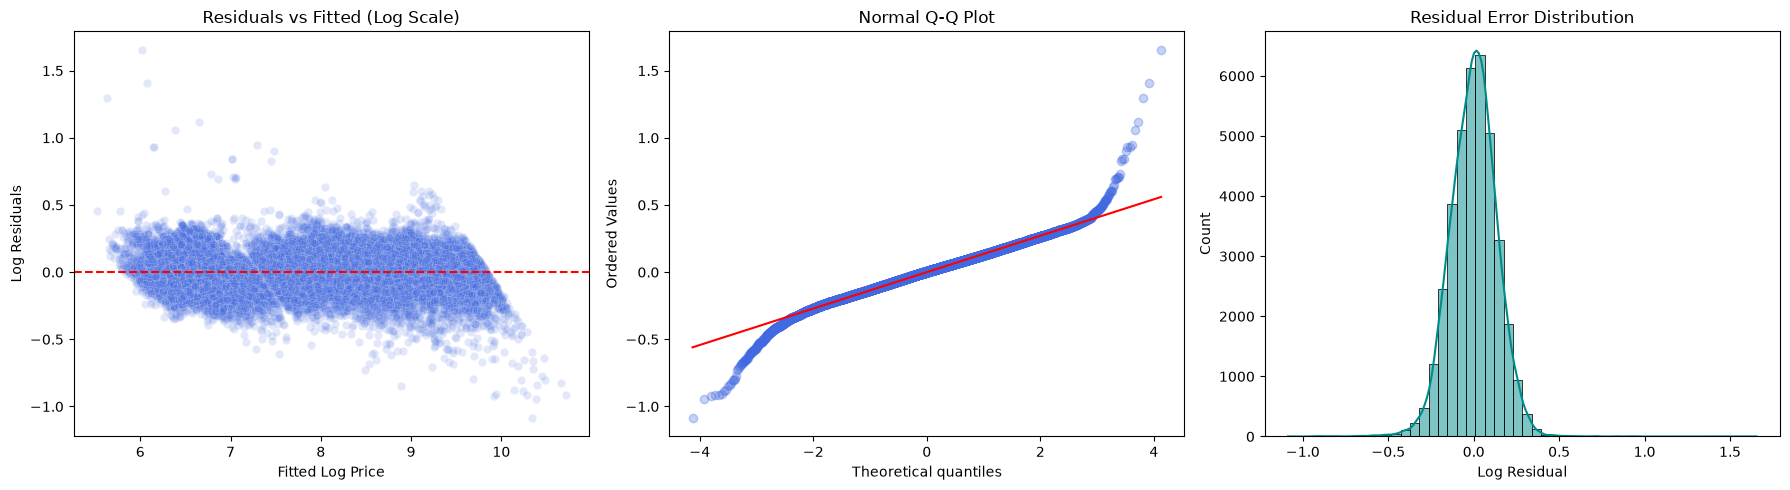

In [7]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Generate in-sample residuals on dev set
y_dev_pred_log = model_final_locked.predict(X_dev_final)
residuals_log = dev_df["log_price"] - y_dev_pred_log

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Linearity & Homoscedasticity: Residuals vs Fitted (Section 10.1 & 10.2)
sns.scatterplot(
    x=y_dev_pred_log, y=residuals_log, alpha=0.15, ax=axes[0], color="royalblue"
)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals vs Fitted (Log Scale)")
axes[0].set_xlabel("Fitted Log Price")
axes[0].set_ylabel("Log Residuals")

# 2. Residual Normality: Q-Q Plot (Section 10.3)
stats.probplot(residuals_log, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_color("royalblue")
axes[1].get_lines()[0].set_alpha(0.3)
axes[1].set_title("Normal Q-Q Plot")

# 3. Residual Distribution Histogram (Section 10.3)
sns.histplot(residuals_log, bins=50, kde=True, ax=axes[2], color="darkcyan")
axes[2].set_title("Residual Error Distribution")
axes[2].set_xlabel("Log Residual")

plt.tight_layout()
plt.show()

In [8]:
# Evaluate out-of-sample prediction bias by Carat Quantile and Cut grade
test_eval_df = test_df.copy()
test_eval_df["pred_dollars"] = np.exp(pred_test_log) * np.mean(
    np.exp(model_final_locked.resid)
)
test_eval_df["abs_error"] = (
    test_eval_df["price"] - test_eval_df["pred_dollars"]
).abs()
test_eval_df["carat_bucket"] = pd.qcut(
    test_eval_df["carat"], q=5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)

subgroup_carat = (
    test_eval_df.groupby("carat_bucket")
    .agg(
        Count=("price", "count"),
        MAE=("abs_error", "mean"),
        Mean_Price=("price", "mean"),
    )
    .round(2)
)

print("=== SUBGROUP STABILITY ACROSS CARAT QUINTILES (Section 12.7) ===")
display(subgroup_carat)

=== SUBGROUP STABILITY ACROSS CARAT QUINTILES (Section 12.7) ===


,Count,MAE,Mean_Price
carat_bucket,,,
Q1,3272,75.45,692.13
Q2,3356,123.35,1211.21
Q3,3429,254.09,2663.59
Q4,2896,583.89,5377.97
Q5,3222,1105.56,10038.88


/var/folders/vp/sf1yj1mj1s587f2m70xcdgzw0000gn/T/ipykernel_53668/3137474251.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dev_df, x='clarity', y='log_price',


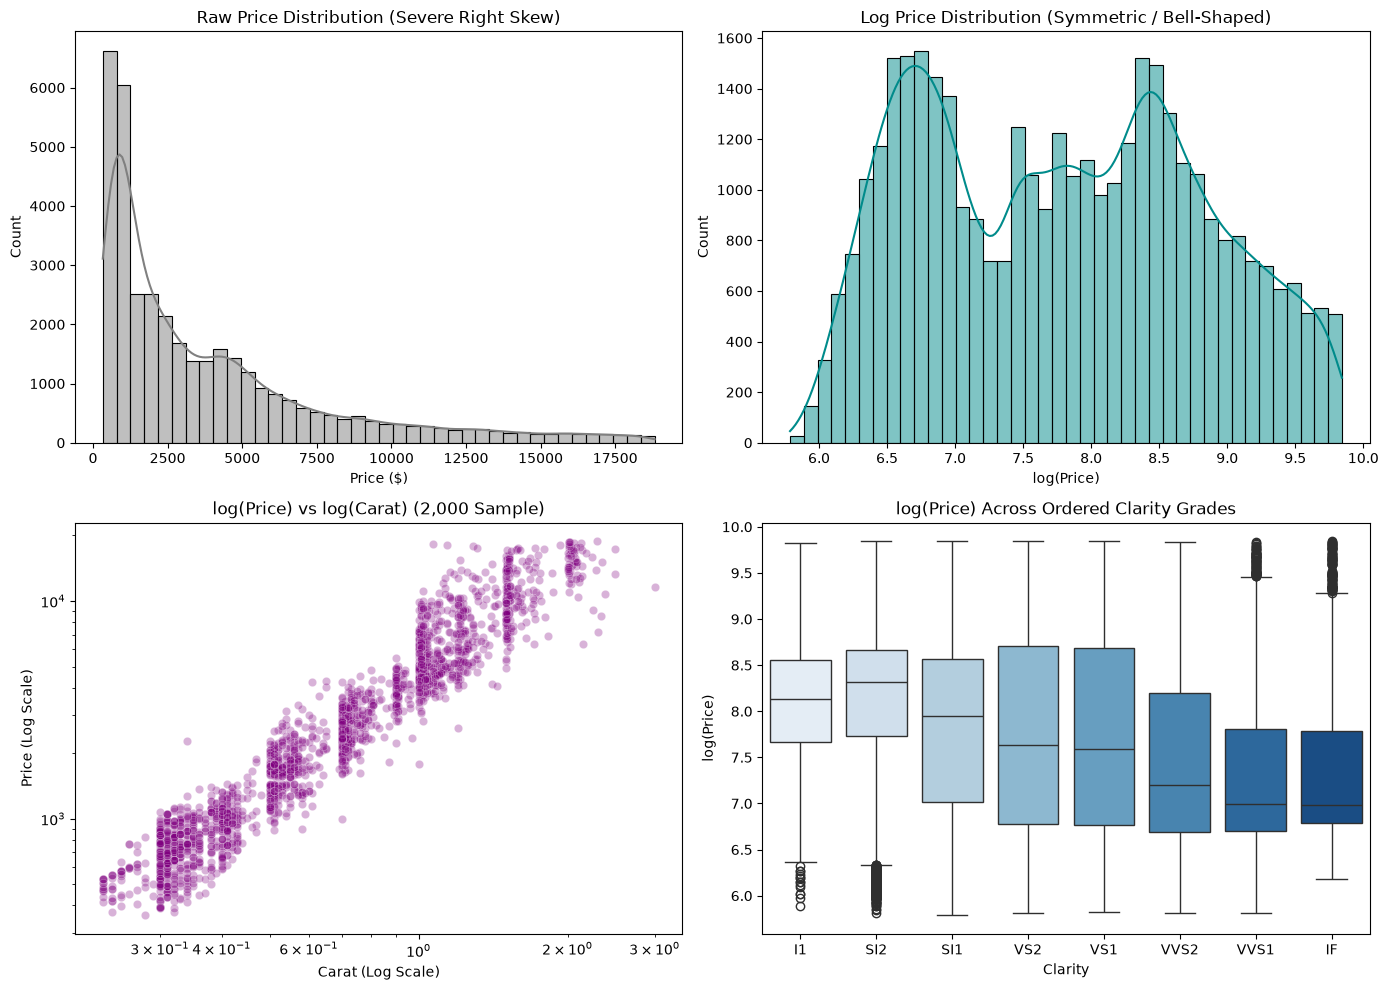

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Target Comparison: Price vs Log(Price) (Section 5.1)
sns.histplot(dev_df['price'], bins=40, kde=True, ax=axes[0, 0], color='gray')
axes[0, 0].set_title('Raw Price Distribution (Severe Right Skew)')
axes[0, 0].set_xlabel('Price ($)')

sns.histplot(dev_df['log_price'], bins=40, kde=True, ax=axes[0, 1], color='darkcyan')
axes[0, 1].set_title('Log Price Distribution (Symmetric / Bell-Shaped)')
axes[0, 1].set_xlabel('log(Price)')

# 2. Key Relationship: Carat vs Price on Log-Log Scale (Section 5.2)
sns.scatterplot(data=dev_df.sample(2000, random_state=42), x='carat', y='price', 
                alpha=0.3, ax=axes[1, 0], color='purple')
axes[1, 0].set_xscale('log')
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('log(Price) vs log(Carat) (2,000 Sample)')
axes[1, 0].set_xlabel('Carat (Log Scale)')
axes[1, 0].set_ylabel('Price (Log Scale)')

# 3. Clarity Premium conditioned on Carat (Section 5.2)
sns.boxplot(data=dev_df, x='clarity', y='log_price', 
            order=['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF'],
            ax=axes[1, 1], palette='Blues')
axes[1, 1].set_title('log(Price) Across Ordered Clarity Grades')
axes[1, 1].set_xlabel('Clarity')
axes[1, 1].set_ylabel('log(Price)')

plt.tight_layout()
plt.show()

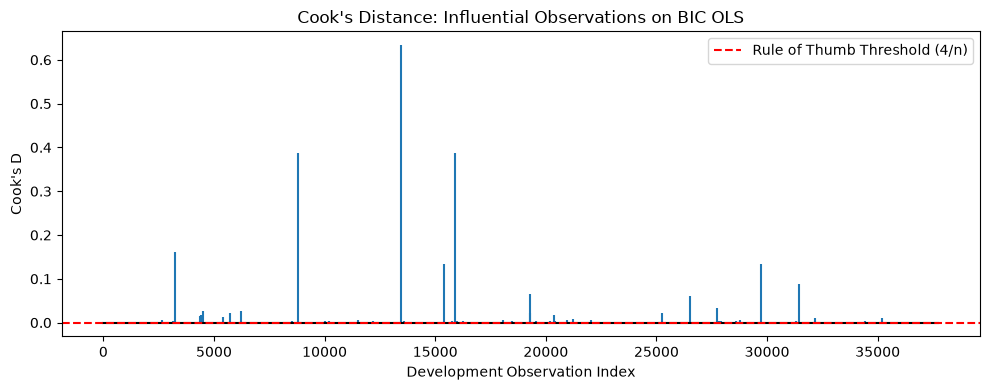

Observations exceeding 4/n Cook's D: 1762 (4.67%)


In [9]:
influence = model_final_locked.get_influence()
cooks_d = influence.cooks_distance[0]

plt.figure(figsize=(10, 4))
plt.stem(np.arange(len(cooks_d)), cooks_d, markerfmt=" ", basefmt="k-")
plt.axhline(4 / len(dev_df), color='red', linestyle='--', label='Rule of Thumb Threshold (4/n)')
plt.title("Cook's Distance: Influential Observations on BIC OLS")
plt.xlabel("Development Observation Index")
plt.ylabel("Cook's D")
plt.legend()
plt.tight_layout()
plt.show()

n_influential = np.sum(cooks_d > (4 / len(dev_df)))
print(f"Observations exceeding 4/n Cook's D: {n_influential} ({n_influential/len(dev_df)*100:.2f}%)")

In [10]:
# Create alternative sample: all non-impossible observations (zeros excluded, extreme dims kept)
raw_path = "data/raw/diamonds.csv"
raw_df_sens = pd.read_csv(raw_path)
non_impossible_df = raw_df_sens[(raw_df_sens['x'] > 0) & (raw_df_sens['y'] > 0) & (raw_df_sens['z'] > 0)].copy()

cut_map = {'Fair': 1, 'Good': 2, 'Very Good': 3, 'Premium': 4, 'Ideal': 5}
color_map = {'J': 1, 'I': 2, 'H': 3, 'G': 4, 'F': 5, 'E': 6, 'D': 7}
clarity_map = {'I1': 1, 'SI2': 2, 'SI1': 3, 'VS2': 4, 'VS1': 5, 'VVS2': 6, 'VVS1': 7, 'IF': 8}
non_impossible_df['cut_score'] = non_impossible_df['cut'].map(cut_map)
non_impossible_df['color_score'] = non_impossible_df['color'].map(color_map)
non_impossible_df['clarity_score'] = non_impossible_df['clarity'].map(clarity_map)
non_impossible_df['log_price'] = np.log(non_impossible_df['price'])

# Transform alternative dataset with same feature builder
fb_sens = DiamondsFeatureBuilder().fit(non_impossible_df)
X_sens = sm.add_constant(fb_sens.transform(non_impossible_df)[bic_cols])
model_sens = sm.OLS(non_impossible_df['log_price'], X_sens).fit(cov_type='HC3')

# Compare dominant coefficients (Section 12.6)
sens_comparison = pd.DataFrame({
    'Clean Sample Beta': model_final_locked.params,
    'All Non-Impossible Beta': model_sens.params,
    'Absolute Shift': (model_final_locked.params - model_sens.params).abs()
}).round(4)

print("=== SENSITIVITY ANALYSIS: CLEAN SAMPLE VS ALL NON-IMPOSSIBLE (Section 12.6) ===")
display(sens_comparison.head(8))

=== SENSITIVITY ANALYSIS: CLEAN SAMPLE VS ALL NON-IMPOSSIBLE (Section 12.6) ===


,Clean Sample Beta,All Non-Impossible Beta,Absolute Shift
const,3.0855,4.5184,1.4329
log_carat,1.2663,1.5175,0.2512
log_carat_sq,0.0473,0.0483,0.0010
log_volume,0.5855,0.3311,0.2543
aspect_xy,1.0856,0.9582,0.1274
depth_c,0.0003,-0.0019,0.0022
depth_c_sq,-0.0012,-0.0017,0.0004
table_c,0.0047,0.0039,0.0008
